### Imports

In [1]:
# !pip install lightgbm
# !pip install pybaseball
# !pip install xgboost
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pybaseball import statcast, playerid_reverse_lookup
from pybaseball import cache
cache.enable()
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict, GridSearchCV,\
      cross_val_score, LeaveOneOut, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor,\
    BaggingClassifier, BaggingRegressor, GradientBoostingClassifier, GradientBoostingRegressor,\
    HistGradientBoostingClassifier
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, \
    mean_squared_error, r2_score, balanced_accuracy_score, f1_score, roc_auc_score
import warnings

### Data Preprocessing

In [53]:
df_2026 = statcast('2026-03-25', '2026-04-20')

This is a large query, it may take a moment to complete


100%|██████████| 27/27 [00:00<00:00, 35.38it/s]


In [54]:
df_2026.shape

(101340, 118)

In [55]:
# Sort data chronologically to accurately find the previous pitch in the same at-bat
df_cleaned = df_2026.sort_values(by=['game_date', 'game_pk', 'at_bat_number', 'pitch_number']).reset_index(drop=True)

In [56]:
df_cleaned[['player_name', 'game_date', 'at_bat_number', 'pitch_number', 'strikes', 'events', 'description']].tail()

,player_name,game_date,at_bat_number,pitch_number,strikes,events,description
101335,"Chapman, Aroldis",2026-04-20,84,1,0,NaN,called_strike
101336,"Chapman, Aroldis",2026-04-20,84,2,1,double,hit_into_play
101337,"Chapman, Aroldis",2026-04-20,85,1,0,NaN,called_strike
101338,"Chapman, Aroldis",2026-04-20,85,2,1,NaN,foul_tip
101339,"Chapman, Aroldis",2026-04-20,85,3,2,field_out,hit_into_play


In [47]:
df_2026.columns.tolist()

['pitch_type',
 'game_date',
 'release_speed',
 'release_pos_x',
 'release_pos_z',
 'player_name',
 'batter',
 'pitcher',
 'events',
 'description',
 'spin_dir',
 'spin_rate_deprecated',
 'break_angle_deprecated',
 'break_length_deprecated',
 'zone',
 'des',
 'game_type',
 'stand',
 'p_throws',
 'home_team',
 'away_team',
 'type',
 'hit_location',
 'bb_type',
 'balls',
 'strikes',
 'game_year',
 'pfx_x',
 'pfx_z',
 'plate_x',
 'plate_z',
 'on_3b',
 'on_2b',
 'on_1b',
 'outs_when_up',
 'inning',
 'inning_topbot',
 'hc_x',
 'hc_y',
 'tfs_deprecated',
 'tfs_zulu_deprecated',
 'umpire',
 'sv_id',
 'vx0',
 'vy0',
 'vz0',
 'ax',
 'ay',
 'az',
 'sz_top',
 'sz_bot',
 'hit_distance_sc',
 'launch_speed',
 'launch_angle',
 'effective_speed',
 'release_spin_rate',
 'release_extension',
 'game_pk',
 'fielder_2',
 'fielder_3',
 'fielder_4',
 'fielder_5',
 'fielder_6',
 'fielder_7',
 'fielder_8',
 'fielder_9',
 'release_pos_y',
 'estimated_ba_using_speedangle',
 'estimated_woba_using_speedangle',
 'w

In [57]:
df_cleaned['LHP'] = df_cleaned['p_throws'].isin(['L']).astype(int)
df_cleaned['LHH'] = df_cleaned['stand'].isin(['L']).astype(int)

# 1. Mirror Release Position (Make everyone 'look' like a Righty to the model)
# If LHP, multiply by -1 so +2.0 becomes -2.0
df_cleaned['release_pos_x_adj'] = df_cleaned['release_pos_x'] * np.where(df_cleaned['LHP'] == 1, -1, 1)

# 2. Mirror Spin Axis
# We reflect LHP spin axis (e.g., 160 becomes 200, 270 becomes 90)
# We use modulo 360 just in case we hit an exact 0/360 boundary
df_cleaned['spin_axis_adj'] = np.where(
    df_cleaned['LHP'] == 1, 
    (360 - df_cleaned['spin_axis']) % 360, 
    df_cleaned['spin_axis']
)

df_cleaned['pfx_x_adj'] = (
    df_cleaned['pfx_x'] * np.where(df_cleaned['LHP'] == 1, -1, 1)
).astype(float)

# Standardize plate_x so that Positive (+) is always OUTSIDE and Negative (-) is always INSIDE
# We multiply by -1 only if the batter is a Lefty (LHH == 1)
df_cleaned['plate_x_adj'] = df_cleaned['plate_x'] * np.where(df_cleaned['LHH'] == 1, -1, 1)

In [58]:
metrics = [
    'release_speed', 'release_pos_x_adj', 'release_pos_z', 
    'release_extension', 'spin_axis_adj', 'release_spin_rate', 
    'pfx_x_adj', 'pfx_z', 'plate_x_adj', 'plate_z'
]

In [59]:
# Create shifted columns for the previous pitch in the same at-bat
for metric in metrics:
    df_cleaned[f'prev_{metric}'] = df_cleaned.groupby(['game_pk', 'at_bat_number'])[metric].shift(1)

df_cleaned[f'prev_description'] = df_cleaned.groupby(['game_pk', 'at_bat_number'])['description'].shift(1)

In [60]:
df_cleaned.tail()

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,prev_release_pos_x_adj,prev_release_pos_z,prev_release_extension,prev_spin_axis_adj,prev_release_spin_rate,prev_pfx_x_adj,prev_pfx_z,prev_plate_x_adj,prev_plate_z,prev_description
101335,SI,2026-04-20,98.3,0.44,6.14,"Chapman, Aroldis",682985,547973,NaN,called_strike,...,<NA>,<NA>,<NA>,NaN,<NA>,NaN,<NA>,<NA>,<NA>,NaN
101336,SI,2026-04-20,98.8,0.55,6.24,"Chapman, Aroldis",682985,547973,double,hit_into_play,...,-0.44,6.14,7.3,193.0,2547,-0.81,1.62,-0.278572,2.005254,called_strike
101337,SL,2026-04-20,86.6,0.51,6.37,"Chapman, Aroldis",693307,547973,NaN,called_strike,...,<NA>,<NA>,<NA>,NaN,<NA>,NaN,<NA>,<NA>,<NA>,NaN
101338,FS,2026-04-20,90.9,0.42,6.27,"Chapman, Aroldis",693307,547973,NaN,foul_tip,...,-0.51,6.37,7.1,74.0,2220,0.92,0.34,0.122013,2.30058,called_strike
101339,FS,2026-04-20,91.6,0.57,6.28,"Chapman, Aroldis",693307,547973,field_out,hit_into_play,...,-0.42,6.27,7.4,184.0,1097,-0.05,0.35,0.345813,2.462383,foul_tip


In [61]:
# Filter to only pitches where there are 2 strikes
df_2strike = df_cleaned[df_cleaned['strikes'] == 2].copy()

df_2strike['pfx_x_adj'] = df_2strike['pfx_x_adj']*12
df_2strike['pfx_z'] = df_2strike['pfx_z']*12
df_2strike['prev_pfx_x_adj'] = df_2strike['prev_pfx_x_adj']*12
df_2strike['prev_pfx_z'] = df_2strike['prev_pfx_z']*12

# Calculate the difference between the current pitch and the previous pitch
for metric in metrics:
    df_2strike[f'diff_{metric}'] = df_2strike[metric] - df_2strike[f'prev_{metric}']

df_2strike = pd.get_dummies(
    df_2strike, 
    columns=['n_thruorder_pitcher'], 
    prefix='thruorder',   # Adds 'thruorder_' to the start of the new columns
    drop_first=True,      # Drops the first category to avoid multicollinearity (the 'dummy trap')
    dtype=int             # Returns 0s and 1s instead of True/False
)

df_2strike = pd.get_dummies(
    df_2strike, 
    columns=['prev_description'], 
    prefix='prev_description', 
    drop_first=False,      
    dtype=int             # Returns 0s and 1s instead of True/False
)

df_2strike = pd.get_dummies(
    df_2strike, 
    columns=['balls'], 
    prefix='ball', 
    drop_first=True,      
    dtype=int             # Returns 0s and 1s instead of True/False
)

df_2strike['is_strikeout'] = df_2strike['events'].isin(['strikeout', 'strikeout_double_play']).astype(int)

# Get a list of the newly created dummy columns
dummy_cols = [col for col in df_2strike.columns if col.startswith('thruorder_')]

dummy_cols = dummy_cols + [col for col in df_2strike.columns if col.startswith('prev_description')]

dummy_cols = dummy_cols + [col for col in df_2strike.columns if col.startswith('ball_')]

# Create a clean version of your metrics without the original variable
continuous_metrics = [m for m in metrics if m != 'n_thruorder_pitcher']

diff_metrics = [f'diff_{m}' for m in continuous_metrics] 

handedness = ['LHP', 'LHH']

# Build the final feature list: metrics + differences + dummy columns
feature_cols = continuous_metrics + dummy_cols + diff_metrics

cols_to_check = feature_cols + ['is_strikeout']

df_model_data = df_2strike.dropna(subset=cols_to_check)

X = df_model_data[feature_cols]
y = df_model_data['is_strikeout']

display(X.head())
display(y.value_counts())

,release_speed,release_pos_x_adj,release_pos_z,release_extension,spin_axis_adj,release_spin_rate,pfx_x_adj,pfx_z,plate_x_adj,plate_z,...,diff_release_speed,diff_release_pos_x_adj,diff_release_pos_z,diff_release_extension,diff_spin_axis_adj,diff_release_spin_rate,diff_pfx_x_adj,diff_pfx_z,diff_plate_x_adj,diff_plate_z
2,92.9,-1.72,5.04,6.9,235.0,2062,-12.48,9.6,0.53002,3.911511,...,7.5,0.27,0.21,0.1,-43.0,485,-1.08,17.52,0.834966,2.600932
3,87.1,-2.04,4.81,6.8,274.0,1582,-13.32,-6.6,0.09506,1.51478,...,-5.8,-0.32,-0.23,-0.1,39.0,-480,-0.84,-16.2,-0.434959,-2.396731
4,86.9,-1.97,4.78,7.0,274.0,1491,-11.88,-5.16,-0.62265,1.233533,...,-0.2,0.07,-0.03,0.2,0.0,-91,1.44,1.44,-0.71771,-0.281247
5,93.6,-1.67,5.07,6.8,242.0,2005,-11.16,9.48,-0.302577,3.132554,...,6.7,0.3,0.29,-0.2,-32.0,514,0.72,14.64,0.320072,1.899021
11,93.7,-1.64,5.12,6.9,238.0,2016,-13.80,11.64,0.384828,3.505351,...,1.7,0.08,0.14,0.0,-4.0,129,2.76,12.36,0.788526,0.074739


is_strikeout
0    23700
1     5707
Name: count, dtype: int64

In [12]:
df_model_data.to_csv('model_data.csv')

In [63]:
descriptive_df = df_model_data.groupby('pitch_name')[['release_speed', 'release_spin_rate', 'pfx_x_adj', 'pfx_z']].mean().round(2)\
    .sort_values(by='release_speed', ascending=False)
display(descriptive_df)

,release_speed,release_spin_rate,pfx_x_adj,pfx_z
pitch_name,,,,
4-Seam Fastball,95.03,2319.2,-7.85,15.99
Sinker,94.26,2187.29,-15.54,7.85
Pitch Out,90.05,2359.5,-7.08,16.14
Cutter,89.62,2402.46,2.75,7.49
Split-Finger,86.37,1300.66,-10.61,2.52
Slider,86.36,2448.53,4.44,0.74
Changeup,86.32,1742.02,-14.63,3.76
Forkball,83.47,1145.44,-11.34,0.93
Knuckleball,83.45,337.0,-1.98,-2.07


In [64]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set: {X_train_clf.shape[0]} 2-strike pitches")
print(f"Testing set: {X_test_clf.shape[0]} 2-strike pitches")
print(f"\nStrikeout rate in train: {y_train_clf.mean()*100:.1f}%")
print(f"Strikeout rate in test:  {y_test_clf.mean()*100:.1f}%")

Training set: 23525 2-strike pitches
Testing set: 5882 2-strike pitches

Strikeout rate in train: 19.4%
Strikeout rate in test:  19.4%


### Decision Tree

In [66]:
dt_clf_full = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt_clf_full.fit(X_train_clf, y_train_clf)
y_pred = dt_clf_full.predict(X_test_clf)
train_acc = balanced_accuracy_score(y_train_clf, dt_clf_full.predict(X_train_clf))
test_acc = balanced_accuracy_score(y_test_clf, y_pred)
cm = confusion_matrix(y_test_clf, y_pred)
cm_df = pd.DataFrame(cm, 
                     index=['Actual Negative', 'Actual Positive'], 
                     columns=['Predicted Negative', 'Predicted Positive'])
print("=== UNPRUNED Decision Tree Classifier Using Validation Set ===")
print(f"Training bal_acc:         {train_acc:.4f}")
print(f"Validation set bal_acc:   {test_acc:.4f}")
print("\nConfusion Matrix:")
print(cm_df)

=== UNPRUNED Decision Tree Classifier Using Validation Set ===
Training bal_acc:         1.0000
Validation set bal_acc:   0.5259

Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative                3877                 863
Actual Positive                 875                 267


In [67]:
path_clf = DecisionTreeClassifier(random_state=42, class_weight='balanced').cost_complexity_pruning_path(
    X_train_clf, y_train_clf
)
ccp_alphas_clf = path_clf.ccp_alphas
impurities_clf = path_clf.impurities
print(f"Number of alpha values to test: {len(ccp_alphas_clf)}")
print(f"Smallest alpha (no pruning):    {ccp_alphas_clf[0]:.6f}")
print(f"Largest alpha (root only):      {ccp_alphas_clf[-1]:.6f}")

Number of alpha values to test: 2320
Smallest alpha (no pruning):    0.000000
Largest alpha (root only):      0.008384


In [68]:
alphas_to_test = ccp_alphas_clf[::int(len(ccp_alphas_clf)/100)]

# 2. Set up the grid search
param_grid = {'ccp_alpha': alphas_to_test}

# We use n_jobs=-1 to use all available CPU cores
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid=param_grid,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=2,
    verbose=1
)

# 3. Fit the model
grid_search.fit(X_train_clf, y_train_clf)

# 4. Extract results
best_alpha_clf = grid_search.best_params_['ccp_alpha']
best_cv_clf = grid_search.best_score_

print(f"Best ccp_alpha: {best_alpha_clf:.6f}")
print(f"Best CV balanced_acc_score: {best_cv_clf:.4f}")

# Optional: Access the full results for plotting
results = pd.DataFrame(grid_search.cv_results_)

Fitting 5 folds for each of 101 candidates, totalling 505 fits
Best ccp_alpha: 0.000617
Best CV balanced_acc_score: 0.5992


In [69]:
best_dt_clf = grid_search.best_estimator_

test_bal_acc = balanced_accuracy_score(y_test_clf, best_dt_clf.predict(X_test_clf))
print(f"Test Balanced Accuracy: {test_bal_acc:.4f}")
print(f"Final Tree Depth: {best_dt_clf.get_depth()}")
print(f"Final Leaf Count: {best_dt_clf.get_n_leaves()}")

cm_pruned = confusion_matrix(y_test_clf, best_dt_clf.predict(X_test_clf))
cm_pruned_df = pd.DataFrame(cm_pruned, 
                     index=['Actual Negative', 'Actual Positive'], 
                     columns=['Predicted Negative', 'Predicted Positive'])
print(f'\n {cm_pruned_df}')

Test Balanced Accuracy: 0.6144
Final Tree Depth: 12
Final Leaf Count: 28

                  Predicted Negative  Predicted Positive
Actual Negative                2027                2713
Actual Positive                 227                 915


In [70]:
best_dt_clf.fit(X_train_clf, y_train_clf)
train_acc_p_val = balanced_accuracy_score(y_train_clf, best_dt_clf.predict(X_train_clf))
test_acc_p_val  = balanced_accuracy_score(y_test_clf,  best_dt_clf.predict(X_test_clf))
print("=== PRUNED Decision Tree Classifier Using Validation Set ===")
print(f"Training balanced accuracy:        {train_acc_p_val:.4f}")
print(f"Validation set balanced accuracy:  {test_acc_p_val:.4f}")
print(f"Tree Depth:        {best_dt_clf.get_depth()}")
print(f"Number of Leaves:  {best_dt_clf.get_n_leaves()}")
print(f"\nGap = {train_acc_p_val - test_acc_p_val:.4f}")
print(f"Compare: Unpruned had depth {dt_clf_full.get_depth()}, "
      f"{dt_clf_full.get_n_leaves()} leaves")

cm_pruned = confusion_matrix(y_test_clf, best_dt_clf.predict(X_test_clf))
cm_pruned_df = pd.DataFrame(cm_pruned, 
                     index=['Actual Negative', 'Actual Positive'], 
                     columns=['Predicted Negative', 'Predicted Positive'])
print(f'\n {cm_pruned_df}')

=== PRUNED Decision Tree Classifier Using Validation Set ===
Training balanced accuracy:        0.6219
Validation set balanced accuracy:  0.6144
Tree Depth:        12
Number of Leaves:  28

Gap = 0.0075
Compare: Unpruned had depth 45, 3892 leaves

                  Predicted Negative  Predicted Positive
Actual Negative                2027                2713
Actual Positive                 227                 915


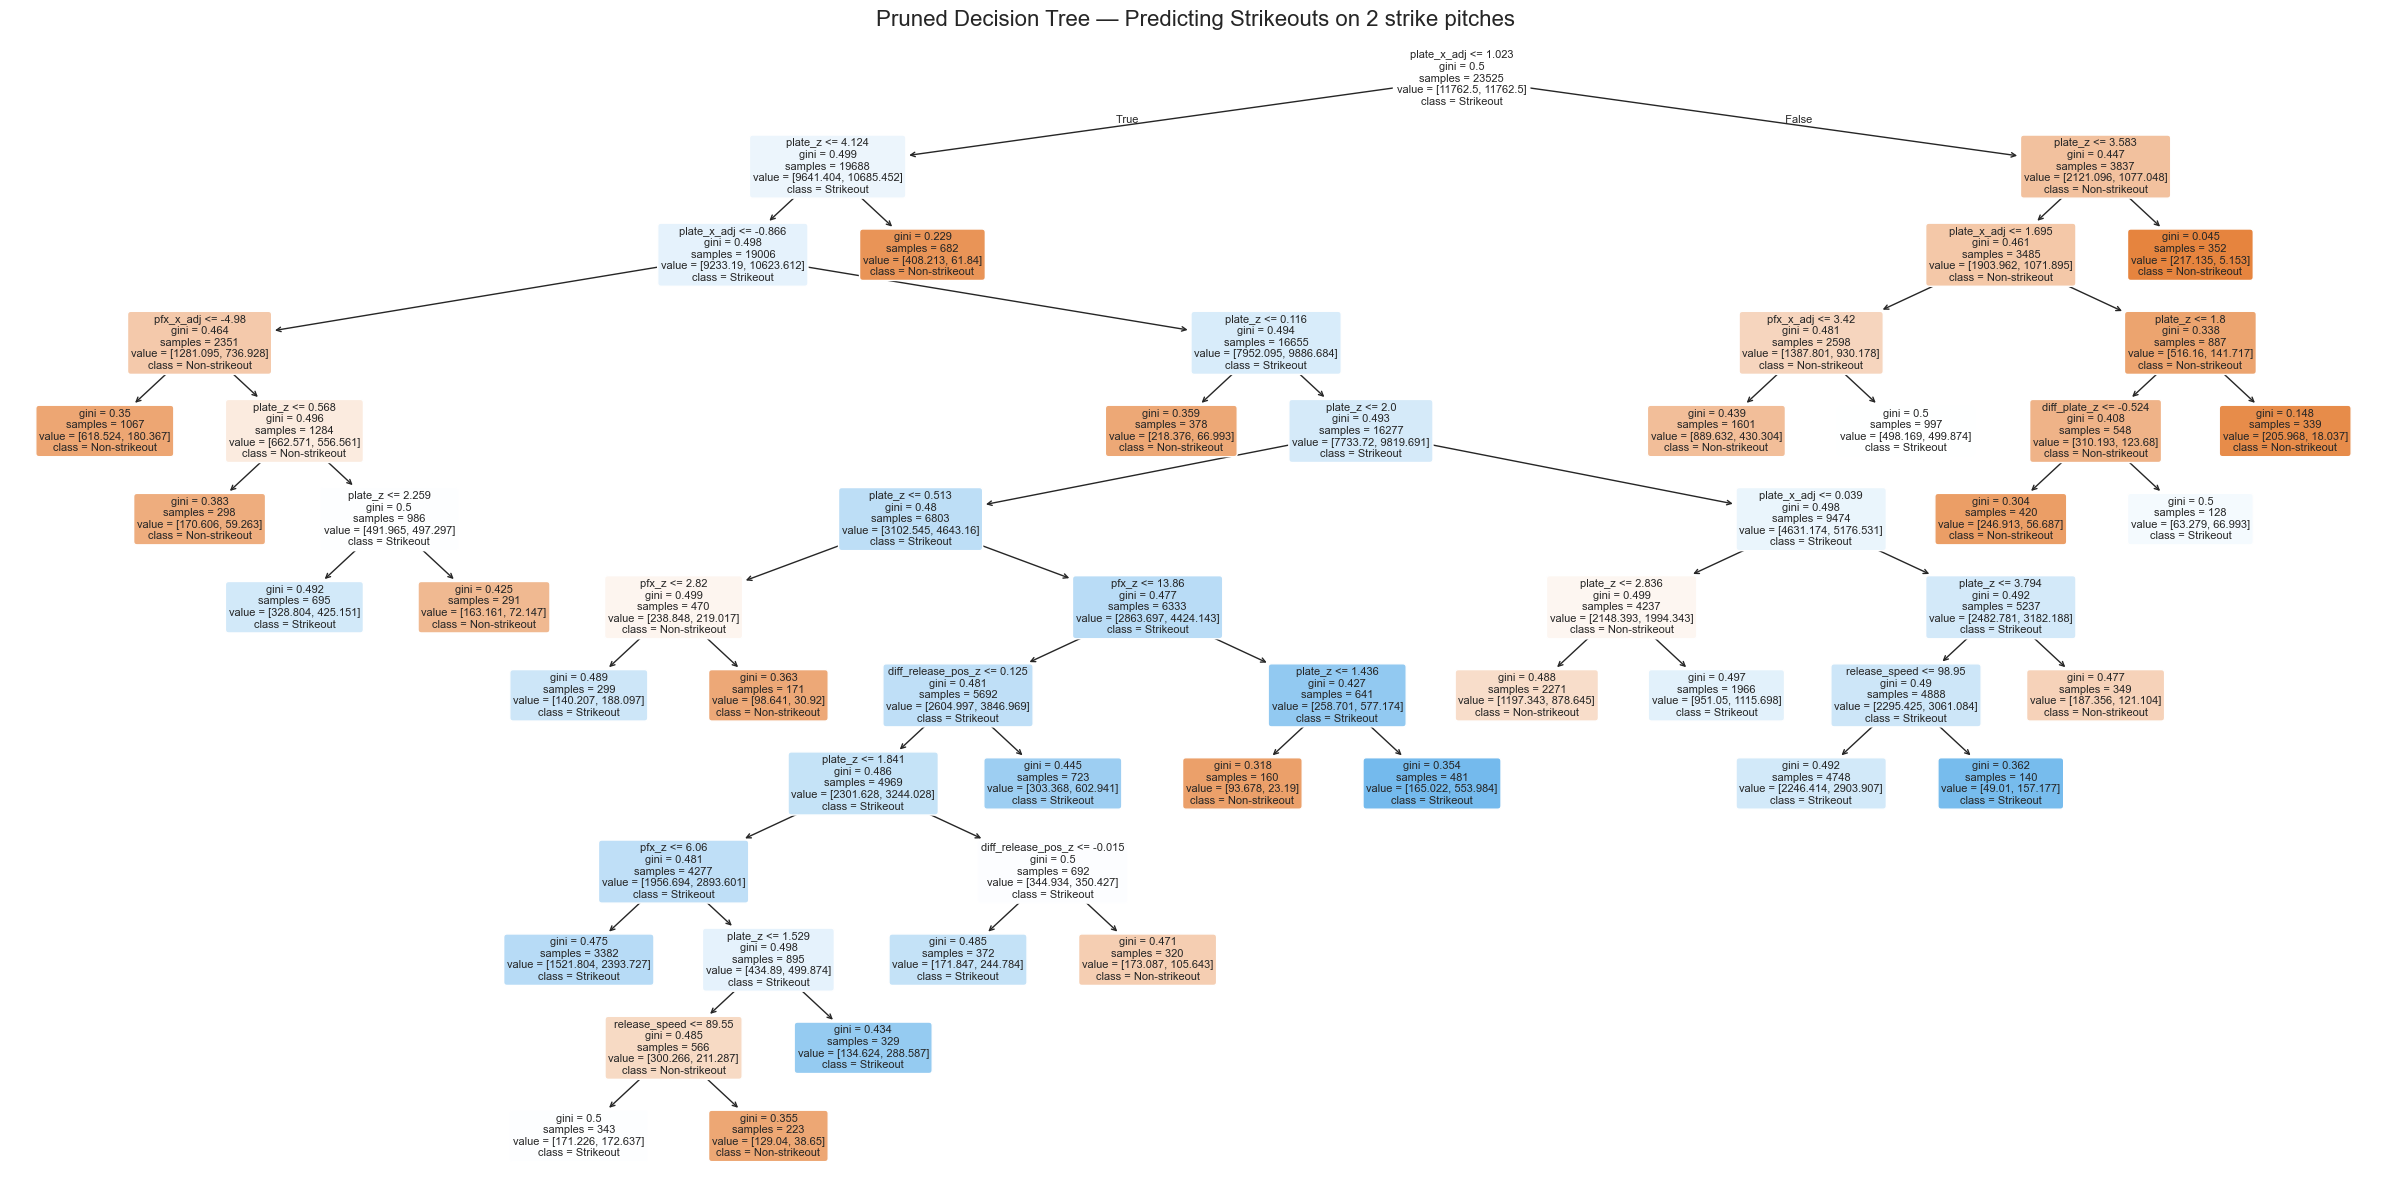

This pruned tree: 28 leaves, depth 12


In [72]:
plt.figure(figsize=(24, 12))
plot_tree(
    best_dt_clf,
    filled=True,
    feature_names=feature_cols,
    class_names=['Non-strikeout', 'Strikeout'],
    rounded=True,
    fontsize=8,
    proportion=False
)
plt.title('Pruned Decision Tree — Predicting Strikeouts on 2 strike pitches', fontsize=16)
plt.tight_layout()
plt.show()
print(f"This pruned tree: {best_dt_clf.get_n_leaves()} leaves, "
      f"depth {best_dt_clf.get_depth()}")

### Ensemble Models

In [73]:
clf_models = {
    'Decision Tree (Pruned)': best_dt_clf,
    'Bagging': BaggingClassifier(
        estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=3),
        n_estimators=100, 
        max_samples=0.7, # Only use 80% of data per tree to increase diversity
        random_state=42, 
        n_jobs=-1
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, 
        max_depth=12,         
        max_features='sqrt', 
        min_samples_leaf=100, 
        class_weight='balanced', 
        random_state=42, 
        n_jobs=-1
    ),
    
    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=300,         # Equivalent to n_estimators
        max_depth=6,         
        learning_rate=0.03,  # Slow and steady
        l2_regularization=0.5, # Add a penalty for complexity
        early_stopping=True,
        class_weight='balanced', 
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300, 
        learning_rate=0.03, 
        max_depth=6, 
        reg_lambda=1.0,      # L2 regularization to prevent overfitting
        scale_pos_weight=3,  # Handling your 75/25 split
        random_state=42, 
        eval_metric='logloss', 
        n_jobs=-1
    ),
    
    'LightGBM': LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=6,
        num_leaves=31,          # Critical for LGBM: usually 2^(max_depth) - 1
        class_weight='balanced', 
        reg_lambda=0.5,         # L2 regularization
        importance_type='gain', # Makes feature importance similar to XGBoost
        random_state=42, 
        n_jobs=-1,
        verbose=-1              # Quiets the extra log output
    )
}

In [74]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

clf_results = {}
for name, model in clf_models.items():
    cv = cross_val_score(model, X_train_clf, y_train_clf, cv=skf, scoring='balanced_accuracy', verbose=1)
    model.fit(X_train_clf, y_train_clf)

    y_pred_test = model.predict(X_test_clf)
    test_accuracy = balanced_accuracy_score(y_test_clf, y_pred_test)
    clf_results[name] = {
        'CV Mean': cv.mean(), 'CV Std': cv.std(), 'Balanced Test Accuracy': test_accuracy
    }

clf_df = pd.DataFrame(clf_results).T.sort_values('Balanced Test Accuracy', ascending=False)
print("\n=== CLASSIFIER RESULTS (sorted by Balanced Test Accuracy) ===")
clf_df.round(4)

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.4s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    6.1s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.5s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   10.2s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.3s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    4.4s finished



=== CLASSIFIER RESULTS (sorted by Balanced Test Accuracy) ===


,CV Mean,CV Std,Balanced Test Accuracy
LightGBM,0.6132,0.0022,0.6289
Hist Gradient Boosting,0.6127,0.0059,0.6276
Decision Tree (Pruned),0.6049,0.0089,0.6144
Random Forest,0.5982,0.0085,0.6095
XGBoost,0.5803,0.0029,0.5971
Bagging,0.5852,0.0058,0.5819


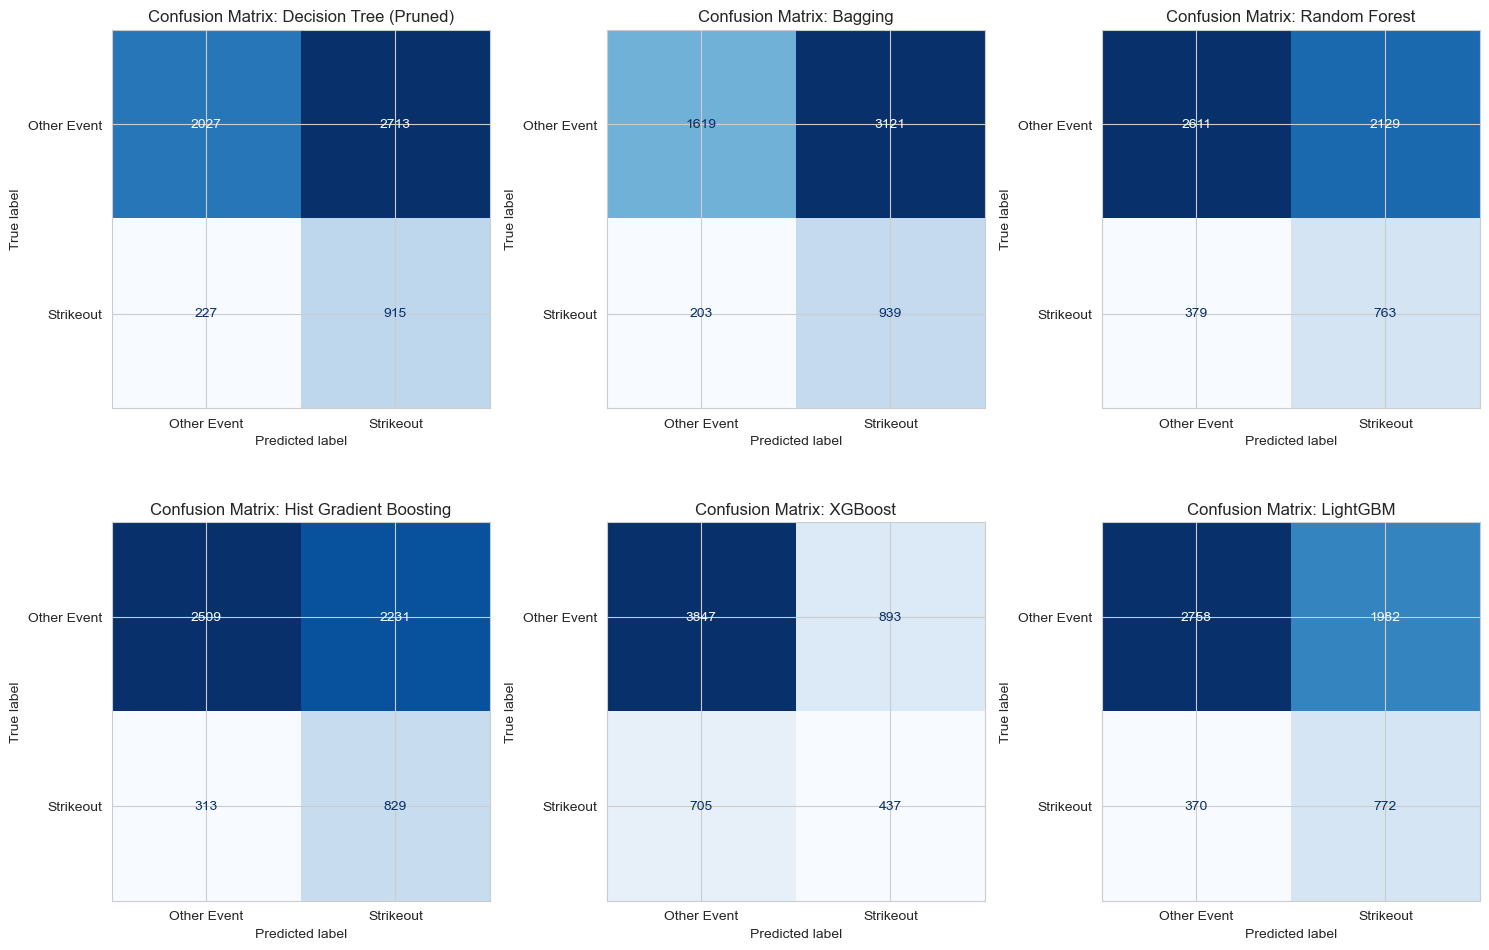

In [116]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(clf_models.items()):
    # Ensure the model is fitted (though your previous loop did this)
    model.fit(X_train_clf, y_train_clf)
    
    # Plot directly to the specific subplot
    disp = ConfusionMatrixDisplay.from_estimator(
        model, 
        X_test_clf, 
        y_test_clf, 
        display_labels=['Other Event', 'Strikeout'],
        cmap='Blues',
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(f"Confusion Matrix: {name}")

# 3. Clean up empty subplots (if you have 5 models, the 6th spot is empty)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

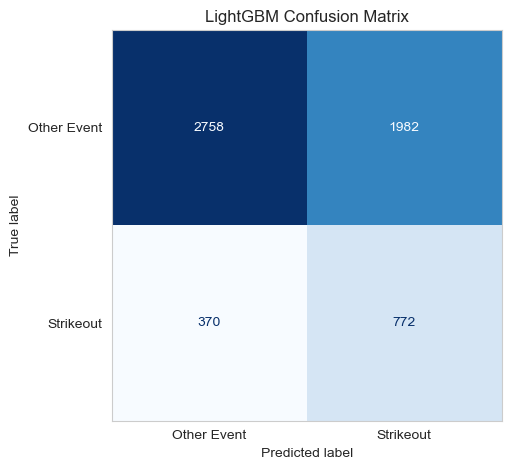

In [117]:
plt.figure(figsize=(8, 5))

# Plot the matrix (removed the ax=axes[i] parameter)
ConfusionMatrixDisplay.from_estimator(
    clf_models['LightGBM'], 
    X_test_clf, 
    y_test_clf, 
    display_labels=['Other Event', 'Strikeout'],
    cmap='Blues',
    colorbar=False
)

plt.grid(False)
plt.title("LightGBM Confusion Matrix")
plt.tight_layout()
plt.show()

In [118]:
from sklearn.inspection import permutation_importance

# 1. Isolate your best model from the dictionary
best_model = clf_models['LightGBM']

# 2. Calculate Permutation Importance
# We use the test set to evaluate true generalization impact
result = permutation_importance(
    best_model, 
    X_test_clf, 
    y_test_clf, 
    n_repeats=10, 
    random_state=42, 
    scoring='balanced_accuracy'
)

/var/folders/5w/fy15m2jx24x4hzy7c3jp79nh0000gp/T/ipykernel_78103/1852232893.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


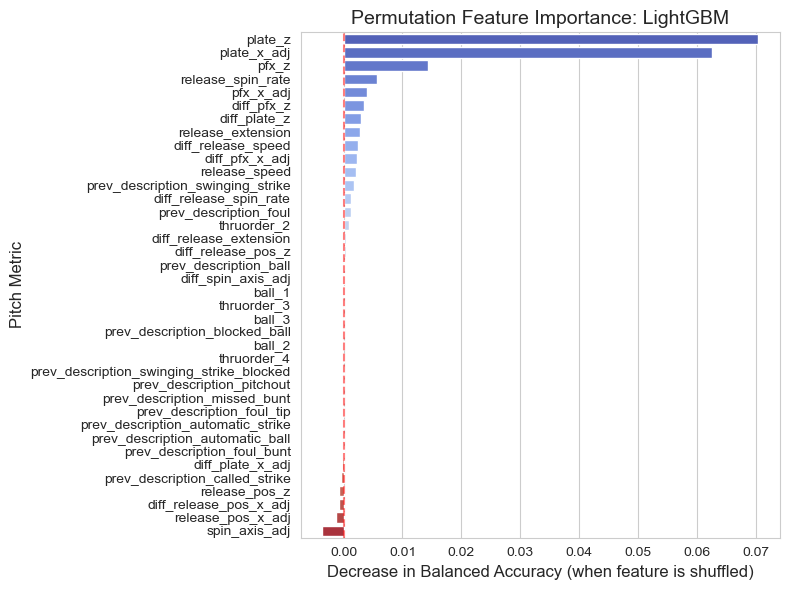

--- Top 10 Drivers of Strikeout Predictions ---
           Feature  Importance
           plate_z      0.0704
       plate_x_adj      0.0626
             pfx_z      0.0144
 release_spin_rate      0.0057
         pfx_x_adj      0.0039
        diff_pfx_z      0.0036
      diff_plate_z      0.0030
 release_extension      0.0028
diff_release_speed      0.0024
    diff_pfx_x_adj      0.0023


In [126]:
# 3. Organize into a clean DataFrame
importance_df = pd.DataFrame({
    'Feature': X_train_clf.columns,
    'Importance': result.importances_mean,
    'Std Dev': result.importances_std
}).sort_values(by='Importance', ascending=False)

# 4. Plotting a single, focused chart
plt.figure(figsize=(8, 6))
sns.set_style("whitegrid")

sns.barplot(
    x='Importance', 
    y='Feature', 
    data=importance_df, 
    palette='coolwarm'
)

plt.title("Permutation Feature Importance: LightGBM", fontsize=14)
plt.xlabel("Decrease in Balanced Accuracy (when feature is shuffled)", fontsize=12)
plt.ylabel("Pitch Metric", fontsize=12)

# Reference line: features to the left of this are 'Noise'
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5) 

plt.tight_layout()
plt.show()

# Quick text output for the Top 5
print("--- Top 10 Drivers of Strikeout Predictions ---")
print(importance_df[['Feature', 'Importance']].head(10).round(4).to_string(index=False))

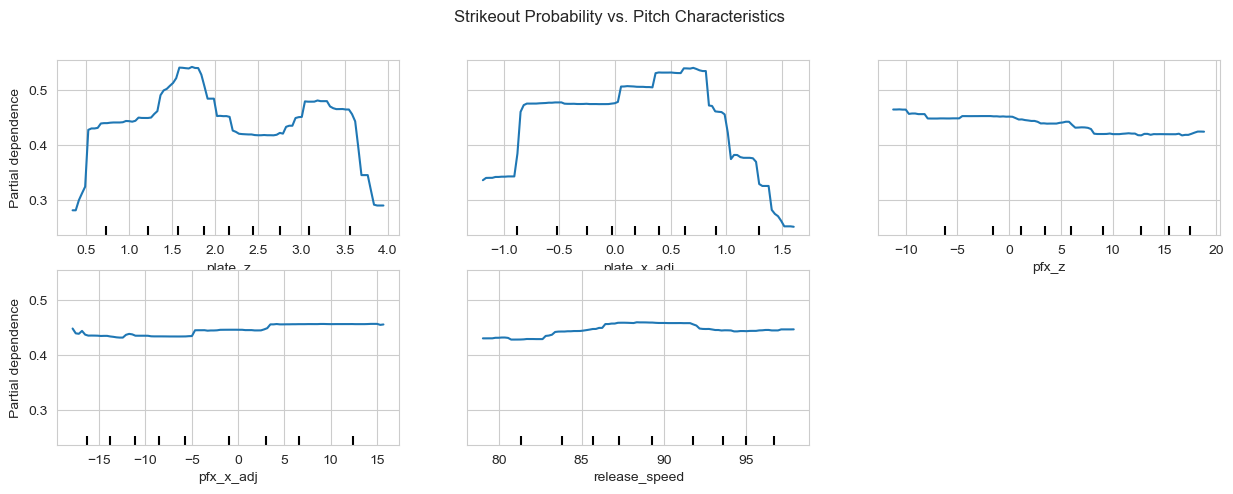

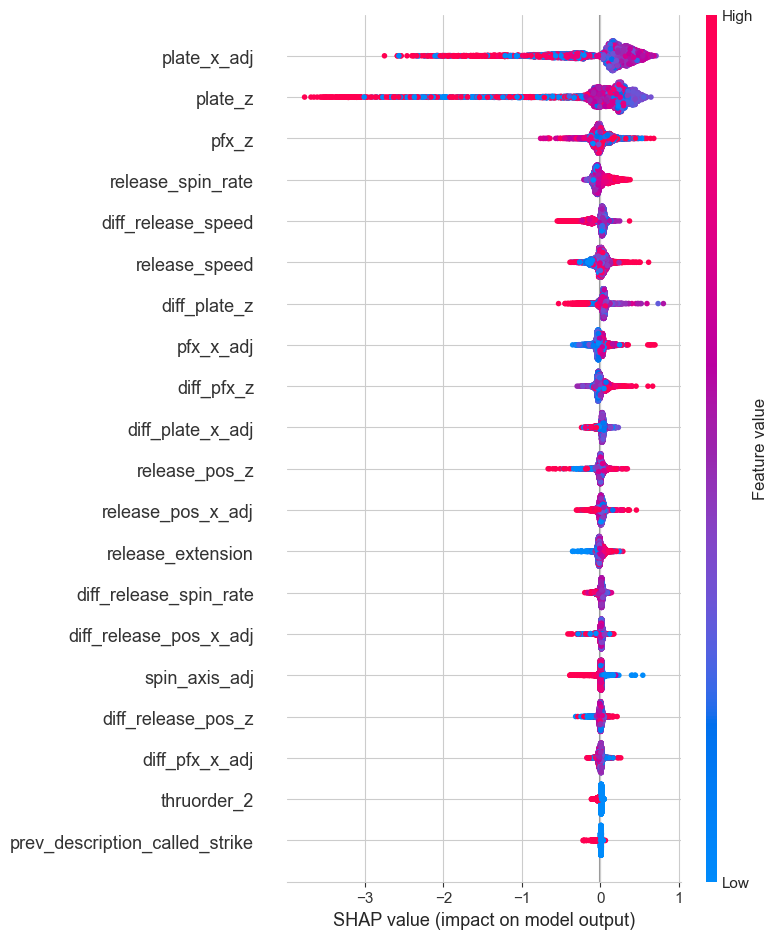

In [127]:
# !pip install shap
from sklearn.inspection import PartialDependenceDisplay
import shap
from numpy import random

# 1. Partial Dependence Plot (PDP)
# Let's look at your most important features (e.g., Velocity and Spin)
features_to_plot = ['plate_z', 'plate_x_adj', 'pfx_z', 'pfx_x_adj', 'release_speed']

fig, ax = plt.subplots(figsize=(15, 5))
PartialDependenceDisplay.from_estimator(
    best_model, 
    X_train_clf, 
    features_to_plot,
    ax=ax
)
plt.suptitle("Strikeout Probability vs. Pitch Characteristics")
plt.show()

# 2. Re-run the explainer
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test_clf)

plt.figure()
shap.summary_plot(shap_values, X_test_clf)


### Statistical Significance

In [83]:
from scipy import stats

# Define feature sets
current_features = [m for m in feature_cols if not m.startswith('prev_') and not m.startswith('diff_')]
full_features = feature_cols

# Get CV scores for both (using Balanced Accuracy or ROC AUC)
scores_a = cross_val_score(best_model, X_train_clf[current_features], y_train_clf, cv=10, scoring='balanced_accuracy')
scores_b = cross_val_score(best_model, X_train_clf[full_features], y_train_clf, cv=10, scoring='balanced_accuracy')

# Perform T-test
t_stat, p_val = stats.ttest_rel(scores_b, scores_a)

In [128]:
print(f'Full model 10-fold CV Balanced Accuracy score: {np.mean(scores_b).round(4)}')
print(f'Model without previous pitch 10-fold CV Balanced Accuracy score: {np.mean(scores_a).round(4)}')
print(f"Mean Balanced Accuracy Improvement: {np.mean(scores_b) - np.mean(scores_a):.4f}")
print(f"P-value: {p_val:.4f}")

Full model 10-fold CV Balanced Accuracy score: 0.6088
Model without previous pitch 10-fold CV Balanced Accuracy score: 0.6144
Mean Balanced Accuracy Improvement: -0.0055
P-value: 0.1561


### Examining specific pitch predictions

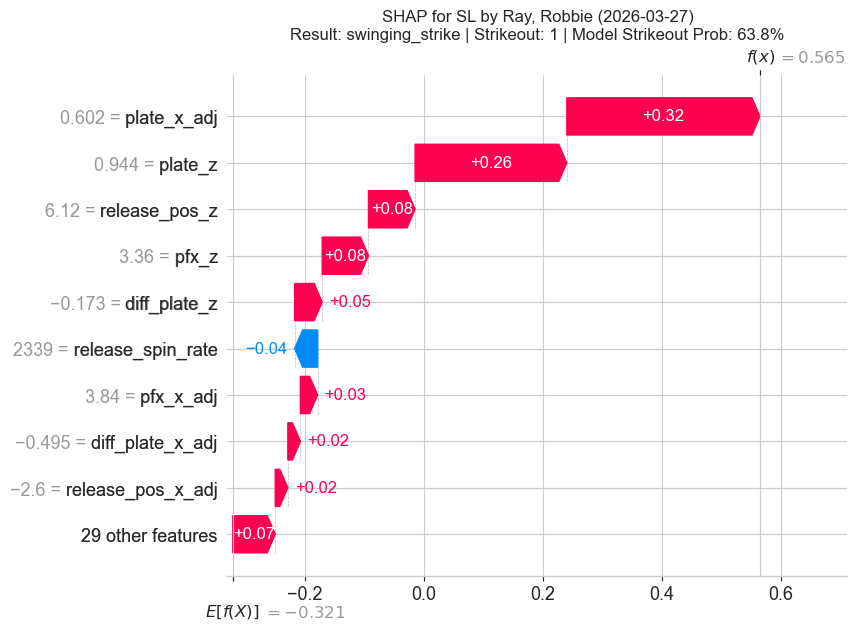

In [134]:
from scipy.special import expit

# 3. Plot the logic for a random prediction in the sample
idx = random.randint(0, len(X_test_clf)-1)

original_idx = X_test_clf.index[idx]
original_row = df_model_data.loc[[original_idx]] # Using double brackets returns a DataFrame view
pitch_thrown = original_row['pitch_type'].values[0]
pitcher = original_row['player_name'].values[0]
date = original_row['game_date'].dt.date.values[0]
result = original_row['description'].values[0]
strikeout = original_row['is_strikeout'].values[0]

raw_log_odds = shap_values[idx].values.sum() + shap_values[idx].base_values
# Convert to probability
prob_f_x = expit(raw_log_odds) 

# Update title with the human-readable probability
plt.title(f"SHAP for {pitch_thrown} by {pitcher} ({date})\n"
          f"Result: {result} | Strikeout: {strikeout} | "
          f"Model Strikeout Prob: {prob_f_x:.1%}")

# plt.title(f"SHAP Waterfall for {pitch_thrown} thrown by {pitcher} on {date}. Result: {result}. Strikeout: {strikeout}")
shap.plots.waterfall(shap_values[idx])

In [86]:
# 1. Sum the SHAP values and base value (this gives raw log-odds)
log_odds_all = shap_values.values.sum(axis=1) + shap_values.base_values

# 2. Convert log-odds to Probabilities to match the Waterfall plot
prob_all = expit(log_odds_all) # Equivalent to: 1 / (1 + np.exp(-log_odds_all))

# 3. Find the index of the highest probability prediction
max_idx = np.argmax(prob_all)
max_prob = prob_all[max_idx]
max_log_odds = log_odds_all[max_idx]

# 4. Retrieve the original data for this "highest" case
original_max_idx = X_test_clf.index[max_idx]
max_row = df_model_data.loc[[original_max_idx]]

print(f"Highest Probability f(x) is {max_prob:.2%} (Raw log-odds: {max_log_odds:.4f}) at array index {max_idx}")
display(max_row)

Highest Probability f(x) is 86.85% (Raw log-odds: 1.8880) at array index 1091


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,prev_description_foul_bunt,prev_description_foul_tip,prev_description_missed_bunt,prev_description_pitchout,prev_description_swinging_strike,prev_description_swinging_strike_blocked,ball_1,ball_2,ball_3,is_strikeout
49861,FF,2026-04-07,100.5,-1.58,5.3,"Misiorowski, Jacob",575929,694819,strikeout,called_strike,...,0,0,0,0,1,0,0,1,0,1


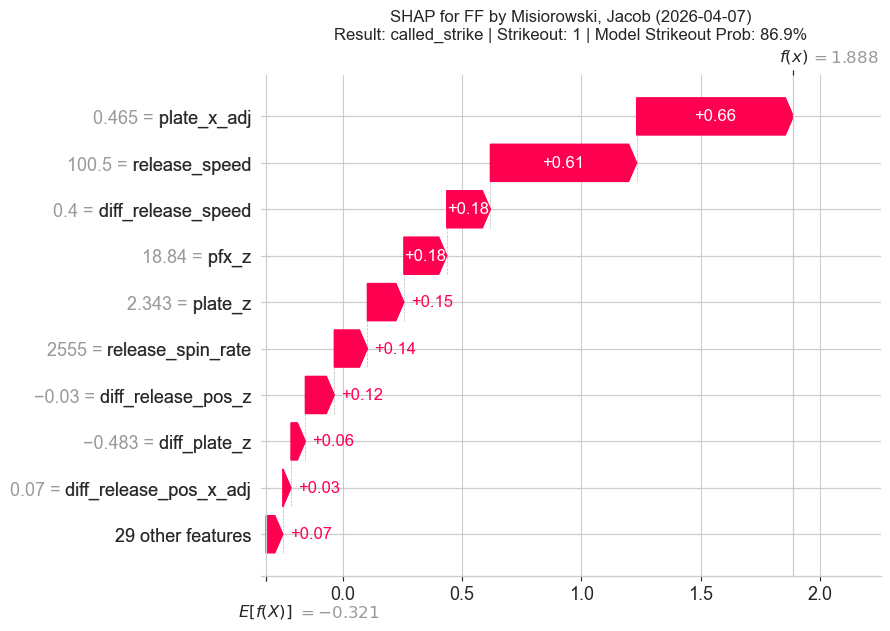

In [87]:
# Use the max_idx we just found!
best_idx = X_test_clf.index[max_idx]
best_row = df_model_data.loc[[best_idx]]
pitch_thrown = best_row['pitch_type'].values[0]
pitcher = best_row['player_name'].values[0]
date = best_row['game_date'].dt.date.values[0]
result = best_row['description'].values[0]
strikeout = best_row['is_strikeout'].values[0]

raw_log_odds = shap_values[max_idx].values.sum() + shap_values[max_idx].base_values
# Convert to probability
prob_f_x = expit(raw_log_odds) 

# Update title with the human-readable probability
plt.title(f"SHAP for {pitch_thrown} by {pitcher} ({date})\n"
          f"Result: {result} | Strikeout: {strikeout} | "
          f"Model Strikeout Prob: {prob_f_x:.1%}")

shap.plots.waterfall(shap_values[max_idx])

The pitch video: https://www.mlb.com/video/willson-contreras-called-out-on-strikes-ianwtm?q=HitResult%20%3D%20%5B%22Strikeout%22%5D%20AND%20PlayerId%20%3D%3D%20%5B694819%5D%20AND%20Season%20%3D%20%5B2026%5D%20Order%20By%20PitchSpeed%20DESC&cp=MIXED&p=0

In [88]:
# 3. Find the index of the second highest probability prediction
# argsort sorts in ascending order; [-2] retrieves the second-largest value's index
second_max_idx = np.argsort(prob_all)[-2]

second_max_prob = prob_all[second_max_idx]
second_max_log_odds = log_odds_all[second_max_idx]

# 4. Retrieve the original data for this "second highest" case
original_second_idx = X_test_clf.index[second_max_idx]
second_max_row = df_model_data.loc[[original_second_idx]]

print(f"Second Highest Probability f(x) is {second_max_prob:.2%} (Raw log-odds: {second_max_log_odds:.4f}) at array index {second_max_idx}")
display(second_max_row)

Second Highest Probability f(x) is 84.67% (Raw log-odds: 1.7090) at array index 2529


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,prev_description_foul_bunt,prev_description_foul_tip,prev_description_missed_bunt,prev_description_pitchout,prev_description_swinging_strike,prev_description_swinging_strike_blocked,ball_1,ball_2,ball_3,is_strikeout
52759,FF,2026-04-08,100.6,-1.68,5.85,"Pérez, Eury",701398,691587,NaN,foul,...,0,0,0,0,0,0,0,1,0,0


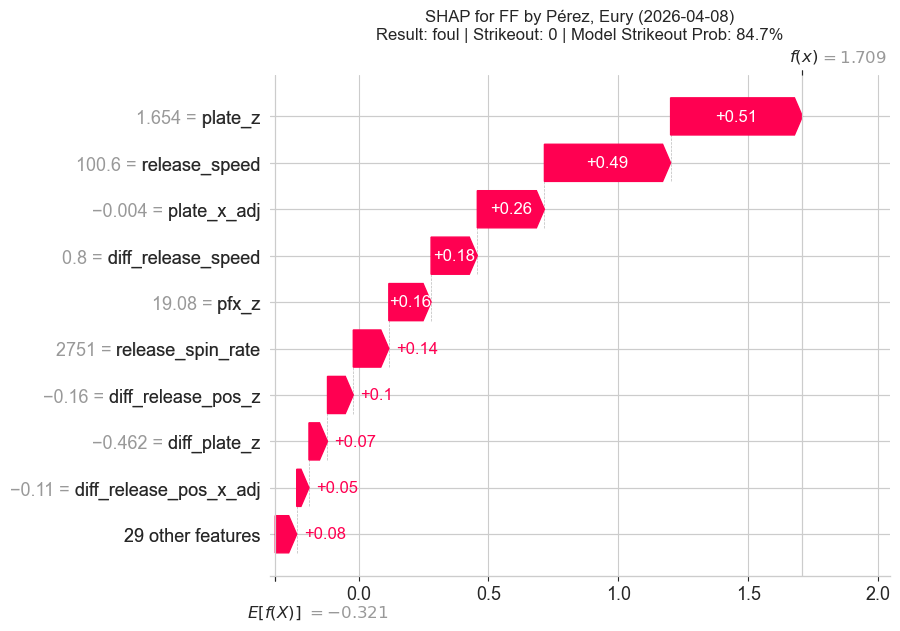

In [89]:
# Use the max_idx we just found!
second_max_idx = np.argsort(prob_all)[-2]
second_best_idx = X_test_clf.index[second_max_idx]
second_best_row = df_model_data.loc[[second_best_idx]]
pitch_thrown = second_best_row['pitch_type'].values[0]
pitcher = second_best_row['player_name'].values[0]
date = second_best_row['game_date'].dt.date.values[0]
result = second_best_row['description'].values[0]
strikeout = second_best_row['is_strikeout'].values[0]

raw_log_odds = shap_values[second_max_idx].values.sum() + shap_values[second_max_idx].base_values
# Convert to probability
prob_f_x = expit(raw_log_odds) 

# Update title with the human-readable probability
plt.title(f"SHAP for {pitch_thrown} by {pitcher} ({date})\n"
          f"Result: {result} | Strikeout: {strikeout} | "
          f"Model Strikeout Prob: {prob_f_x:.1%}")

shap.plots.waterfall(shap_values[second_max_idx])

https://www.mlb.com/video/eury-perez-foul-to-sal-stewart-v0ncob?q=gamePk%20=%20823885%20AND%20Inning%20=%20[1]%20Order%20By%20Timestamp%20ASC&p=0&pt=Pitch%20by%20Pitch%20-%201st%20Inning

previous pitch: https://www.mlb.com/video/eury-perez-ball-to-sal-stewart-50cc64?q=gamePk%20=%20823885%20AND%20Inning%20=%20[1]%20Order%20By%20Timestamp%20ASC&p=0&pt=Pitch%20by%20Pitch%20-%201st%20Inning

pitch video: https://www.mlb.com/video/cam-schlittler-ball-to-rafael-devers?q=gamePk%20=%20823243%20AND%20Inning%20=%20[1]%20Order%20By%20Timestamp%20ASC&p=1&pt=Pitch%20by%20Pitch%20-%201st%20Inning

prev pitch: https://www.mlb.com/video/cam-schlittler-swinging-strike-to-rafael-devers-67tqq9?q=gamePk%20=%20823243%20AND%20Inning%20=%20[1]%20Order%20By%20Timestamp%20ASC&p=1&pt=Pitch%20by%20Pitch%20-%201st%20Inning


### Neural Network

In [27]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1" # Hides GPUs from TF
os.environ["TF_METAL_DEV_RT_DISB"] = "1" # Disables Metal runtime

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.optimizers import Adam

# Force TensorFlow to only see the CPU
tf.config.set_visible_devices([], 'GPU')

print("GPU is disabled. Running on CPU for stability.")

GPU is disabled. Running on CPU for stability.


In [55]:
from sklearn.preprocessing import StandardScaler

# Identify numeric numerical columns vs encoded dummy columns for accurate scaling
numerical_cols = X_train_clf.select_dtypes(include=['int64', 'float64']).columns

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = X_train_clf.copy()
X_test_scaled = X_test_clf.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_clf[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_clf[numerical_cols])

# # 1. Cast to float32 BEFORE tensor conversion (Crucial for M4 stability)
# X_train_f32 = X_train_scaled.values.astype('float32')
# X_test_f32 = X_test_scaled.values.astype('float32')

# # Ensure y is numeric and flat
# y_train_f32 = y_train_clf.values.astype('float32')
# y_test_f32 = y_test_clf.values.astype('float32')

# # 2. Convert to tensors
# X_train_tensor = tf.convert_to_tensor(X_train_f32)
# y_train_tensor = tf.convert_to_tensor(y_train_f32)
# X_test_tensor = tf.convert_to_tensor(X_test_f32)
# y_test_tensor = tf.convert_to_tensor(y_test_f32)

X_train_tensor = tf.convert_to_tensor(X_train_scaled, dtype=tf.float32)
y_train_tensor = tf.convert_to_tensor(y_train_clf, dtype=tf.float32)
X_test_tensor = tf.convert_to_tensor(X_test_scaled, dtype=tf.float32)
y_test_tensor = tf.convert_to_tensor(y_test_clf, dtype=tf.float32)

In [56]:
from tensorflow.keras.metrics import Recall, Precision
from tensorflow.keras.regularizers import l2
from sklearn.utils import class_weight

# Calculate weights based on your training labels
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_clf),
    y=y_train_clf
)
dict_weights = {0: weights[0], 1: weights[1]}

nn1 = Sequential([
    Input(shape=(X_train_tensor.shape[1],)),
    
    # Layer 1: Smaller with L2 regularization
    Dense(20, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.4), # Increased from 0.1 to 0.4
    
    # Layer 2: Even smaller
    Dense(10, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.3),
    
    Dense(1, activation='sigmoid')
])

# nn1.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
nn1.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=[Recall(name='recall'), Precision(name='precision')])

In [57]:
history1 = nn1.fit(
    X_train_tensor, y_train_tensor,
    class_weight=dict_weights,
    epochs=75,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 1s 761us/step - loss: 0.9699 - precision: 0.1985 - recall: 0.4705 - val_loss: 0.8275 - val_precision: 0.2058 - val_recall: 0.2985
Epoch 2/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step - loss: 0.7893 - precision: 0.1980 - recall: 0.5082 - val_loss: 0.7504 - val_precision: 0.2237 - val_recall: 0.5887
Epoch 3/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - loss: 0.7270 - precision: 0.2016 - recall: 0.5853 - val_loss: 0.7079 - val_precision: 0.2222 - val_recall: 0.5073
Epoch 4/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 454us/step - loss: 0.7030 - precision: 0.2063 - recall: 0.5767 - val_loss: 0.6954 - val_precision: 0.2205 - val_recall: 0.6242
Epoch 5/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - loss: 0.6936 - precision: 0.2069 - recall: 0.5320 - val_loss: 0.6866 - val_precision: 0.2206 - val_recall: 0.5741
Epoch 6/75
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - loss: 0.6909 - precision: 0.2076 - recall: 0.6734 - val_loss: 0.6821 - val_precision: 0.2203 -

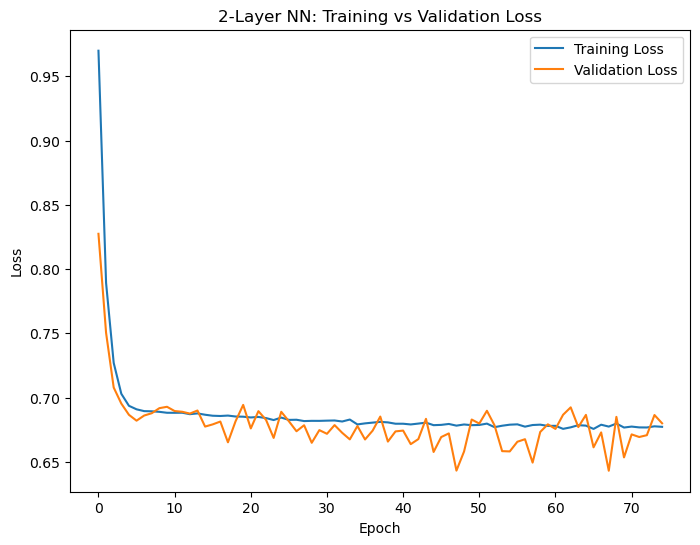

In [58]:
# Plot training and validation loss
plt.figure(figsize=(8, 6))
plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('2-Layer NN: Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [59]:
preds1 = (nn1.predict(X_test_tensor) > 0.5).astype(int)

acc1 = balanced_accuracy_score(y_test_clf, preds1)
conf_matrix1 = confusion_matrix(y_test_clf, preds1)

print(f"Test Accuracy for 2-Layer NN: {acc1:.4f}")
cm_df = pd.DataFrame(conf_matrix1, 
                     index=['Actual Negative', 'Actual Positive'], 
                     columns=['Predicted Negative', 'Predicted Positive'])
print(cm_df)


184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step
Test Accuracy for 2-Layer NN: 0.5922
                 Predicted Negative  Predicted Positive
Actual Negative                1887                2853
Actual Positive                 244                 898


In [41]:
nn2 = Sequential([
    Input(shape=(X_train_tensor.shape[1],)),
    
    # Layer 1: Broad pattern recognition
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    BatchNormalization(), # Added for stability
    Dropout(0.4),
    
    # Layer 2: Feature interaction
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    BatchNormalization(),
    Dropout(0.3),
    
    # Layer 3: Abstract refinement
    Dense(8, activation='relu'),
    Dropout(0.2),
    
    Dense(1, activation='sigmoid')
])

nn2.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=[Recall(name='recall'), Precision(name='precision')])

In [42]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Early Stopping: The "Quit While You're Ahead" monitor
# This prevents the model from continuing to "memorize" training data 
# once the validation performance stops improving.
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,               # Slightly more breathing room for the LR reducer to work
    restore_best_weights=True, # Crucial: rolls back to the best epoch, not the last one
    verbose=1
)

# 2. ReduceLROnPlateau: The "Focus" monitor
# When the loss flatlines, we shrink the learning rate (the "step size")
# to help the model find the absolute bottom of the local minimum.
lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,                # Reduce LR to 20% of its current value (e.g., 0.001 -> 0.0002)
    patience=5,                # If no improvement for 5 epochs, trigger the reduction
    min_lr=1e-6,               # Floor for the learning rate
    verbose=1
)

# 3. The Improved Fit Call
# Note: I increased epochs to 150 because the callbacks will 
# handle the stopping for you automatically.
history2 = nn2.fit(
    X_train_tensor, 
    y_train_tensor,
    validation_split=0.2,      # 20% of data is set aside to check for overfitting
    epochs=150,                
    batch_size=64,
    class_weight=dict_weights, # Handles the strikeout/non-strikeout imbalance
    callbacks=[early_stop, lr_reducer],
    verbose=1
)

Epoch 1/150
295/295 ━━━━━━━━━━━━━━━━━━━━ 1s 954us/step - loss: 1.2050 - precision: 0.1938 - recall: 0.5223 - val_loss: 1.0731 - val_precision: 0.2089 - val_recall: 0.9175 - learning_rate: 0.0010
Epoch 2/150
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 547us/step - loss: 0.9771 - precision: 0.1953 - recall: 0.6160 - val_loss: 0.9224 - val_precision: 0.2090 - val_recall: 0.9228 - learning_rate: 0.0010
Epoch 3/150
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 539us/step - loss: 0.8584 - precision: 0.1974 - recall: 0.6712 - val_loss: 0.8262 - val_precision: 0.2100 - val_recall: 0.8820 - learning_rate: 0.0010
Epoch 4/150
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 546us/step - loss: 0.7840 - precision: 0.1991 - recall: 0.6529 - val_loss: 0.7712 - val_precision: 0.2118 - val_recall: 0.9248 - learning_rate: 0.0010
Epoch 5/150
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step - loss: 0.7427 - precision: 0.2069 - recall: 0.6734 - val_loss: 0.7309 - val_precision: 0.2260 - val_recall: 0.8361 - learning_rate: 0.0010
Epoch 6/150
295/295 ━━━━━

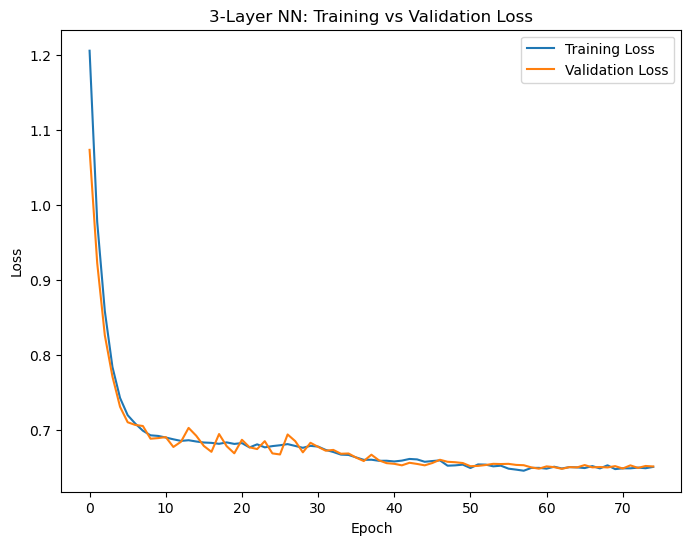

In [43]:
# Plot training and validation loss
plt.figure(figsize=(8, 6))
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('3-Layer NN: Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [44]:
preds2 = (nn2.predict(X_test_tensor) > 0.5).astype(int)

acc2 = balanced_accuracy_score(y_test_clf, preds2)
conf_matrix2 = confusion_matrix(y_test_clf, preds2)

print(f"Test Accuracy for 2-Layer NN: {acc2:.4f}")
cm_df = pd.DataFrame(conf_matrix2, 
                     index=['Actual Negative', 'Actual Positive'], 
                     columns=['Predicted Negative', 'Predicted Positive'])
print(cm_df)


184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 340us/step
Test Accuracy for 2-Layer NN: 0.5920
                 Predicted Negative  Predicted Positive
Actual Negative                2192                2548
Actual Positive                 318                 824


### Unsupervised Learning

In [ ]:
feature_cols2 = continuous_metrics + diff_metrics

In [ ]:
# Gets Rid of All Dummies for PCA, FA, & Clustering

df_new = df_model_data[feature_cols2]

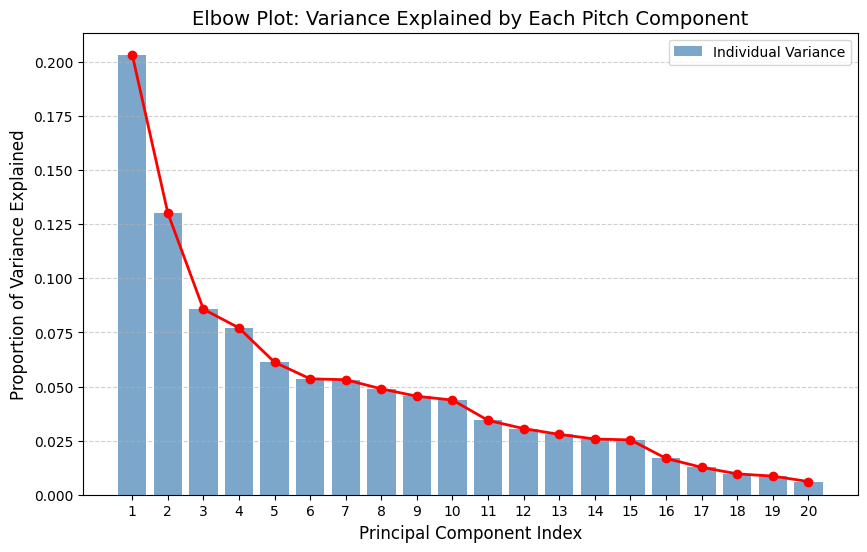

In [ ]:
# 1. Scale numerical diff data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_new)

# 2. Run PCA with all components
pca = PCA()
pca.fit(X_scaled)

# 3. Get the individual variance for each component
exp_var_individual = pca.explained_variance_ratio_

# 4. Create the Scree Plot
plt.figure(figsize=(10, 6))

# Bar chart for individual variance
plt.bar(range(1, len(exp_var_individual) + 1), exp_var_individual,
        color='steelblue', alpha=0.7, label='Individual Variance')

# Line plot to highlight the 'elbow'
plt.plot(range(1, len(exp_var_individual) + 1), exp_var_individual,
         marker='o', color='red', linestyle='-', linewidth=2)

plt.title('Elbow Plot: Variance Explained by Each Pitch Component', fontsize=14)
plt.xlabel('Principal Component Index', fontsize=12)
plt.ylabel('Proportion of Variance Explained', fontsize=12)
plt.xticks(range(1, len(exp_var_individual) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()

plt.show()

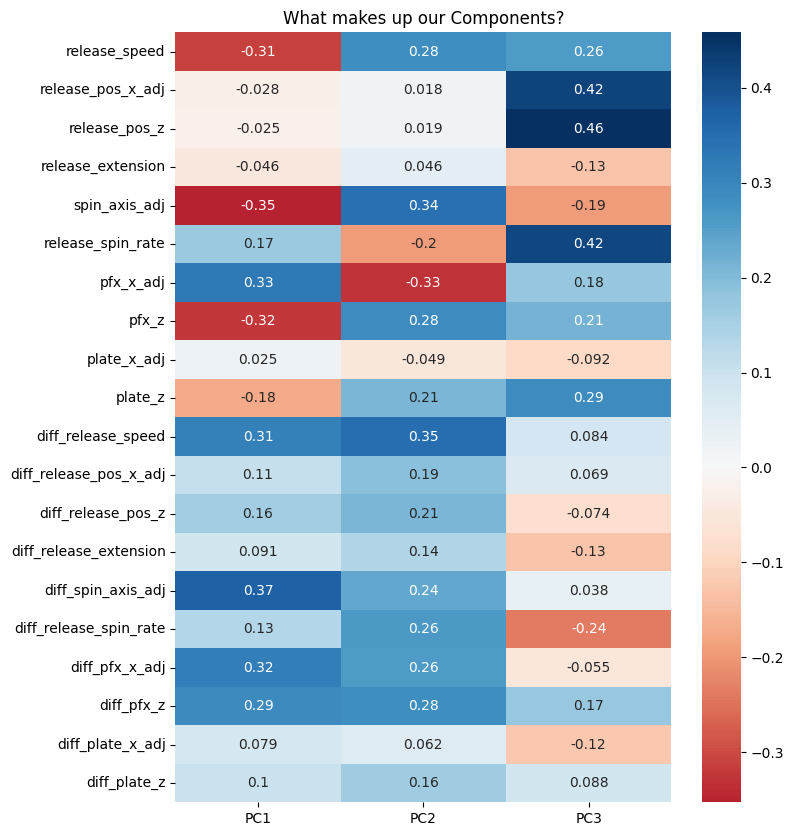

In [ ]:
# 1. Create a DataFrame for the loadings of the first 3 components
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=['PC1', 'PC2', 'PC3'],
    index=df_new.columns
)

# 2. Plotting a Heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(loadings, annot=True, cmap='RdBu', center=0)
plt.title('What makes up our Components?')
plt.show()

In [ ]:
def get_component_structure(pca_loadings_df, threshold=0.3):
    """
    Identifies which variables 'belong' to each PC based on an absolute threshold.
    """
    structure = {}

    for column in pca_loadings_df.columns:
        # Get absolute values to catch strong negative correlations
        loadings = pca_loadings_df[column]
        significant_features = loadings[loadings.abs() >= threshold].sort_values(ascending=False)

        structure[column] = significant_features.to_dict()

    return structure


pc_map = get_component_structure(loadings, threshold=0.3)


for pc, variables in pc_map.items():
    print(f"\n--- {pc} ---")
    if not variables:
        print("No variables met the threshold.")
    for var, val in variables.items():
        print(f"{var}: {val:.3f}")


--- PC1 ---
diff_spin_axis_adj: 0.373
pfx_x_adj: 0.327
diff_pfx_x_adj: 0.316
diff_release_speed: 0.311
release_speed: -0.314
pfx_z: -0.324
spin_axis_adj: -0.353

--- PC2 ---
diff_release_speed: 0.348
spin_axis_adj: 0.344
pfx_x_adj: -0.329

--- PC3 ---
release_pos_z: 0.458
release_pos_x_adj: 0.423
release_spin_rate: 0.416


In [ ]:
from factor_analyzer import FactorAnalyzer

# 1. Initialize FA without a set number to check eigenvalues
fa = FactorAnalyzer(rotation=None)
fa.fit(df_new)

# 2. Check the eigenvalues
ev, v = fa.get_eigenvalues()
print(ev) # Look for values > 1

[4.06603876 2.6034455  1.71446282 1.54139379 1.22408183 1.07126897
 1.06280411 0.97816655 0.90993828 0.87492197 0.68683786 0.61112428
 0.55762145 0.51490074 0.50662784 0.33621337 0.25310113 0.19285767
 0.17208633 0.12210675]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
from sklearn.decomposition import FactorAnalysis
fa = FactorAnalysis(n_components=3)
fa.fit(X_scaled)

FactorAnalysis(n_components=3)

In [ ]:
# Extracting the factor loadings
loadings2 = fa.components_.T
loadings_df2 = pd.DataFrame(loadings2, columns=['Factor 1', 'Factor 2', 'Factoe 3'], index=feature_cols2)
loadings_df2

,Factor 1,Factor 2,Factoe 3
release_speed,-0.686676,0.063030,-0.528850
release_pos_x_adj,-0.010644,-0.026584,-0.115252
release_pos_z,0.011974,-0.041389,-0.152497
release_extension,-0.084929,0.008964,0.022670
spin_axis_adj,-0.933214,0.168053,0.125561
release_spin_rate,0.490499,-0.129235,-0.603030
pfx_x_adj,0.844323,-0.168062,-0.145296
pfx_z,-0.699998,0.040739,-0.476702
plate_x_adj,0.053300,-0.030440,0.051948
plate_z,-0.337436,0.056539,-0.442255


In [ ]:

def get_factor_structure(loadings_df, threshold=0.3):
    """
    Groups variables into factors based on a significance threshold.
    """
    factor_dict = {}

    for column in loadings_df.columns:
        # Get the loadings for this factor
        loadings = loadings_df[column]

        # Filter for values that meet the threshold (absolute value)
        # Then sort so the strongest loading is at the top
        significant = loadings[loadings.abs() >= threshold].sort_values(ascending=False, key=abs)

        factor_dict[column] = significant

    return factor_dict

# 1. Set your threshold (0.3 is standard, 0.4 is strict)
threshold_value = 0.3

# 2. Run the function
factors = get_factor_structure(loadings_df2, threshold=threshold_value)

# 3. Print the results clearly
print(f"--- Variables with Absolute Loading >= {threshold_value} ---")
for factor_name, variables in factors.items():
    print(f"\n{factor_name}:")
    if variables.empty:
        print("  (No variables meet the threshold)")
    else:
        for var, val in variables.items():
            print(f"  {var:25} | {val:7.3f}")

--- Variables with Absolute Loading >= 0.3 ---

Factor 1:
  spin_axis_adj             |  -0.933
  pfx_x_adj                 |   0.844
  pfx_z                     |  -0.700
  release_speed             |  -0.687
  release_spin_rate         |   0.490
  diff_spin_axis_adj        |   0.464
  plate_z                   |  -0.337
  diff_pfx_x_adj            |   0.329
  diff_pfx_z                |   0.304

Factor 2:
  diff_release_speed        |   0.756
  diff_spin_axis_adj        |   0.724
  diff_pfx_x_adj            |   0.677
  diff_pfx_z                |   0.626
  diff_release_spin_rate    |   0.421
  diff_release_pos_z        |   0.302

Factoe 3:
  release_spin_rate         |  -0.603
  release_speed             |  -0.529
  pfx_z                     |  -0.477
  plate_z                   |  -0.442


In [ ]:
from sklearn.decomposition import FactorAnalysis
fa2 = FactorAnalysis(n_components=4)
fa2.fit(X_scaled)

FactorAnalysis(n_components=4)

In [ ]:
# Extracting the factor loadings
loadings3 = fa2.components_.T
loadings_df3 = pd.DataFrame(loadings3, columns=['Factor 1', 'Factor 2', 'Factoe 3', 'Factor 4'], index=feature_cols2)
loadings_df3

,Factor 1,Factor 2,Factoe 3,Factor 4
release_speed,-0.676529,0.061199,-0.548364,-0.024034
release_pos_x_adj,-0.008359,-0.031197,-0.148949,-0.547523
release_pos_z,0.015740,-0.048664,-0.190013,-0.600428
release_extension,-0.084908,0.010538,0.027770,-0.008568
spin_axis_adj,-0.937812,0.173501,0.109763,0.038440
release_spin_rate,0.502641,-0.133066,-0.602478,0.184408
pfx_x_adj,0.844964,-0.169711,-0.122930,0.050089
pfx_z,-0.690661,0.040227,-0.480794,0.032544
plate_x_adj,0.052068,-0.029376,0.055570,0.059290
plate_z,-0.329178,0.055279,-0.438840,0.064646


In [ ]:
def get_factor_structure(loadings_df, threshold=0.3):
    """
    Groups variables into factors based on a significance threshold.
    """
    factor_dict = {}

    for column in loadings_df.columns:
        # Get the loadings for this factor
        loadings = loadings_df[column]

        # Filter for values that meet the threshold (absolute value)
        # Then sort so the strongest loading is at the top
        significant = loadings[loadings.abs() >= threshold].sort_values(ascending=False, key=abs)

        factor_dict[column] = significant

    return factor_dict

# 1. Set threshold
threshold_value = 0.3

# 2. Run the function
factors = get_factor_structure(loadings_df3, threshold=threshold_value)

# 3. Print the results clearly
print(f"--- Variables with Absolute Loading >= {threshold_value} ---")
for factor_name, variables in factors.items():
    print(f"\n{factor_name}:")
    if variables.empty:
        print("  (No variables meet the threshold)")
    else:
        for var, val in variables.items():
            print(f"  {var:25} | {val:7.3f}")

--- Variables with Absolute Loading >= 0.3 ---

Factor 1:
  spin_axis_adj             |  -0.938
  pfx_x_adj                 |   0.845
  pfx_z                     |  -0.691
  release_speed             |  -0.677
  release_spin_rate         |   0.503
  diff_spin_axis_adj        |   0.467
  diff_pfx_x_adj            |   0.334
  plate_z                   |  -0.329
  diff_pfx_z                |   0.309

Factor 2:
  diff_release_speed        |   0.758
  diff_spin_axis_adj        |   0.723
  diff_pfx_x_adj            |   0.687
  diff_pfx_z                |   0.632
  diff_release_spin_rate    |   0.421

Factoe 3:
  release_spin_rate         |  -0.602
  release_speed             |  -0.548
  pfx_z                     |  -0.481
  plate_z                   |  -0.439

Factor 4:
  release_pos_z             |  -0.600
  release_pos_x_adj         |  -0.548


We should choose the 4 Factor Model for Factor Analysis and interpet exactly how the 4 Factor Factor Analysis Groups compare to the 3 Principal Component Principal Component Analysis Groups, and Compare similarities and differences.

K Means Clustering

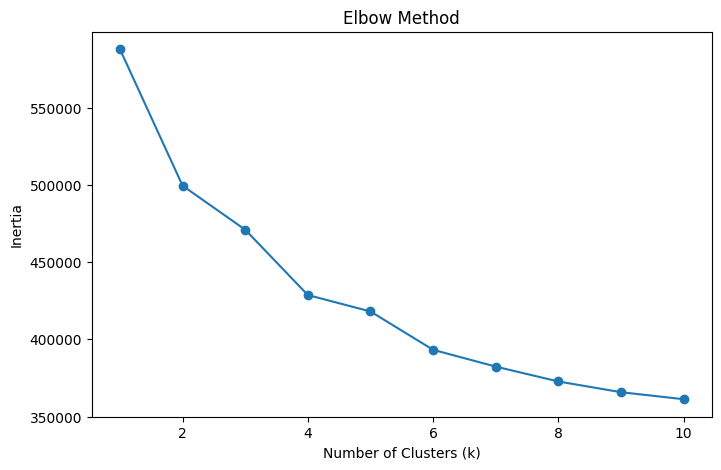

In [ ]:
from sklearn.cluster import KMeans

cluster_range = range(1, 11)
inertias = []

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(cluster_range, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

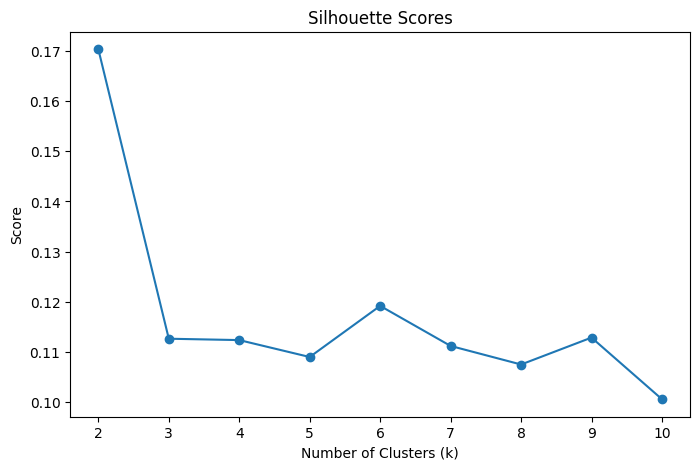

In [ ]:
from sklearn.metrics import silhouette_score

sil_scores = []

for k in range(2, 11):  # silhouette needs k ≥ 2
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)

plt.figure(figsize=(8,5))
plt.plot(range(2, 11), sil_scores, marker='o')
plt.title('Silhouette Scores')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Score')
plt.show()

In [ ]:
df_new

,release_speed,release_pos_x_adj,release_pos_z,release_extension,spin_axis_adj,release_spin_rate,pfx_x_adj,pfx_z,plate_x_adj,plate_z,diff_release_speed,diff_release_pos_x_adj,diff_release_pos_z,diff_release_extension,diff_spin_axis_adj,diff_release_spin_rate,diff_pfx_x_adj,diff_pfx_z,diff_plate_x_adj,diff_plate_z
2,92.9,-1.72,5.04,6.9,235.0,2062,-1.04,0.8,0.53002,3.911511,7.5,0.27,0.21,0.1,43.0,485,0.09,1.46,0.834966,2.600932
3,87.1,-2.04,4.81,6.8,274.0,1582,-1.11,-0.55,0.09506,1.51478,5.8,0.32,0.23,0.1,39.0,480,0.07,1.35,0.434959,2.396731
4,86.9,-1.97,4.78,7.0,274.0,1491,-0.99,-0.43,-0.62265,1.233533,0.2,0.07,0.03,0.2,0.0,91,0.12,0.12,0.71771,0.281247
5,93.6,-1.67,5.07,6.8,242.0,2005,-0.93,0.79,-0.302577,3.132554,6.7,0.3,0.29,0.2,32.0,514,0.06,1.22,0.320072,1.899021
11,93.7,-1.64,5.12,6.9,238.0,2016,-1.15,0.97,0.384828,3.505351,1.7,0.08,0.14,0.0,4.0,129,0.23,1.03,0.788526,0.074739
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101331,88.9,-0.51,6.11,7.6,212.0,844,-0.28,0.38,0.933485,2.53724,10.5,0.04,0.12,0.3,24.0,1623,0.67,0.98,0.91171,0.456003
101332,98.5,-0.49,6.2,7.3,197.0,2243,-1.03,1.28,0.540103,1.733459,9.6,0.02,0.09,0.3,15.0,1399,0.75,0.9,0.393382,0.803781
101333,99.3,-0.42,6.21,7.3,189.0,2334,-1.05,1.23,0.446383,2.047806,0.8,0.07,0.01,0.0,8.0,91,0.02,0.05,0.093721,0.314347
101334,86.4,-0.54,6.24,7.5,56.0,2344,1.25,-0.35,-0.231752,1.278041,12.9,0.12,0.03,0.2,133.0,10,2.30,1.58,0.678135,0.769765


In [ ]:
df_new.loc[:, 'cluster'] = kmeans.fit_predict(X_scaled)

k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=42)
df_new['cluster'] = kmeans.fit_predict(X_scaled)

/tmp/ipykernel_9722/3354666632.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['cluster'] = kmeans.fit_predict(X_scaled)


In [ ]:
# Look at average values per cluster
cluster_summary = df_new.groupby('cluster')[feature_cols2].mean()
print(cluster_summary)

         release_speed  release_pos_x_adj  release_pos_z  release_extension  \
cluster                                                                       
0            84.683271          -1.879467       5.769698           6.390777   
1             92.62334          -1.869821       5.747676           6.478826   
2             82.86996            -1.9485        5.72036           6.388744   
3            91.382171          -1.884549       5.757663           6.476044   

         spin_axis_adj  release_spin_rate  pfx_x_adj     pfx_z  plate_x_adj  \
cluster                                                                       
0            83.911512        2527.795069   0.677249 -0.087004     0.332452   
1           221.965728        2159.799553  -0.826230  0.922771     0.134208   
2            56.360999        2551.004774   0.805916 -0.337677     0.235915   
3           223.743319        2057.061378  -0.810091  0.806027     0.171348   

          plate_z  diff_release_speed  diff_releas

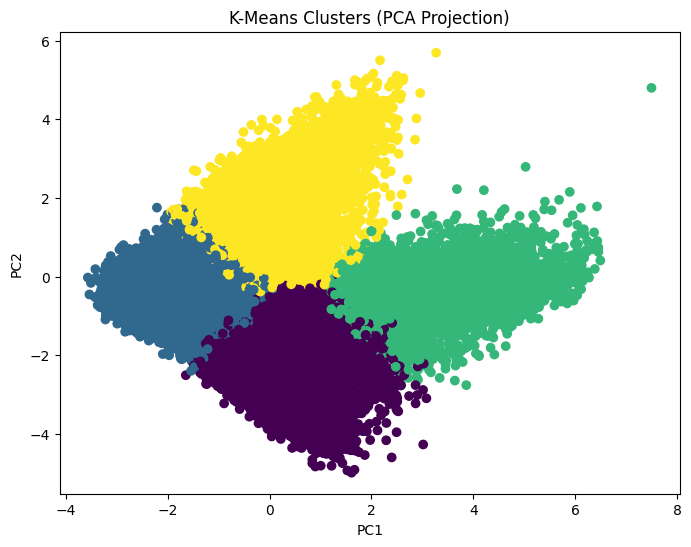

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
plt.scatter(pca_data[:,0], pca_data[:,1], c=df_new['cluster'])
plt.title('K-Means Clusters (PCA Projection)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()